# GNN V1CLD — Sweep par depth

Pour chaque depth B&B, on overfit un GNN sur **un graphe** et on mesure :
- `gap_conv` : écart relatif entre `L1_GNN` et la borne subgradient convergée
- `gap_opt`  : écart relatif entre `L1_GNN` et la solution optimale
- `frac_recov` : fraction de l'amélioration `L1(0) → conv` récupérée par le GNN

**Objectif** : voir si le GNN est plus ou moins efficace en fonction de la profondeur.

## 1. Setup

In [3]:
import sys, importlib
from pathlib import Path
from collections import defaultdict

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

REPO = Path('../').resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import gnn.train_gnn_v1cld as T
importlib.reload(T)
from gnn.train_gnn_v1cld import (
    load_dataset, GNN, lagrangian_v1cld, verify_v1cld,
)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})

## 2. Chargement et groupement par depth

In [4]:
DATA_DIR = REPO / 'data' / 'train_v1cld'
N_VAL    = 10

graphs = load_dataset(
    DATA_DIR / f'instances_n{N_VAL}.txt',
    DATA_DIR / f'nodes_n{N_VAL}.txt',
)

by_depth = defaultdict(list)
for g in graphs:
    by_depth[int(g.context[0].item())].append(g)

depths_available = sorted(by_depth.keys())
print(f'Depths disponibles : {depths_available}')
print()
print(f'  {"depth":>6}  {"nb graphes":>10}  {"n_g":>5}  {"N_z":>5}  {"m":>4}')
print('  ' + '-' * 37)
for d in depths_available:
    g0 = by_depth[d][0]
    print(f'  {d:6d}  {len(by_depth[d]):10d}  {g0.n_g:5d}  {g0.N_z:5d}  {g0.m:4d}')

[load_dataset] 190 graphes chargés, 13 ignorés
Depths disponibles : [0, 1, 2, 3, 4, 5, 6, 7, 8]

   depth  nb graphes    n_g    N_z     m
  -------------------------------------
       0           2     10     50     5
       1           4      9     50     5
       2           8      8     50     5
       3          16      7     50     5
       4          29      6     50     5
       5          46      5     50     5
       6          50      4     50     5
       7          31      3     50     5
       8           4      2     50     5


## 3. Configuration

In [5]:
CFG = dict(
    n_epochs  = 1000,     # epochs d'overfit par graphe
    lr        = 1e-3,
    eta_min   = 1e-5,    # cosine annealing
)

N_DEPTHS          = 10   # combien de depths à explorer (les N premiers disponibles)
GRAPH_IDX         = 0    # indice du graphe dans chaque groupe de depth
PRECISION         = 1    # critère d'arrêt subgradient
PATIENCE          = 30   # patience subgradient
T_SUBGRAD_MAX     = 300  # max itérations pour la référence convergée

## 4. Sweep

In [6]:
def train_one(g, cfg, seed=42):
    """Overfit GNN sur un seul graphe. Retourne (model, best_l1, history)."""
    torch.manual_seed(seed)
    data = g.to(torch.device('cpu'))

    model     = GNN().to('cpu')
    optimizer = torch.optim.Adam(model.parameters(), lr=cfg['lr'])
    sched     = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=cfg['n_epochs'], eta_min=cfg['eta_min'])

    best_l1 = float('inf')
    history = []
    for _ in range(cfg['n_epochs']):
        model.train()
        optimizer.zero_grad()
        loss = lagrangian_v1cld(model(data), data)
        loss.backward()
        optimizer.step()
        sched.step()
        v = loss.item()
        best_l1 = min(best_l1, v)
        history.append(v)

    return model, best_l1, history


depths_to_use = depths_available[:N_DEPTHS]
results = []

for depth in depths_to_use:
    grp = by_depth[depth]
    if GRAPH_IDX >= len(grp):
        print(f'depth={depth}: GRAPH_IDX={GRAPH_IDX} hors bornes ({len(grp)} graphes), skipping')
        continue

    g = grp[GRAPH_IDX]

    with torch.no_grad():
        l1_init = lagrangian_v1cld(torch.zeros(g.N_z * g.m * g.n_g), g).item()
    opt_val = g.opt.item()

    l1_conv, n_iters = verify_v1cld(
        g, T=T_SUBGRAD_MAX, precision=PRECISION, patience=PATIENCE,
        return_n_iters=True)

    model, best_l1, hist = train_one(g, CFG)

    gap_vs_conv  = (best_l1 - l1_conv)  / abs(l1_conv)  * 100
    gap_vs_opt   = (best_l1 - opt_val)  / abs(opt_val)  * 100
    denom_recov  = max(l1_init - l1_conv, 1e-9)
    frac_recov   = (l1_init - best_l1) / denom_recov * 100

    results.append(dict(
        depth=depth, n_g=g.n_g, N_z=g.N_z,
        l1_init=l1_init, l1_conv=l1_conv, n_iters=n_iters,
        l1_gnn=best_l1, opt=opt_val,
        gap_vs_conv=gap_vs_conv, gap_vs_opt=gap_vs_opt,
        frac_recov=frac_recov, history=hist,
    ))

    print(f'depth={depth:3d}  n_g={g.n_g:3d}  N_z={g.N_z:3d}  '
          f'L1_0={l1_init:7.0f}  conv={l1_conv:7.0f}({n_iters:3d}it)  '
          f'GNN={best_l1:7.0f}  opt={opt_val:7.0f}  '
          f'gap_conv={gap_vs_conv:+6.1f}%  recov={frac_recov:5.0f}%')

depth=  0  n_g= 10  N_z= 50  L1_0=   3996  conv=   3137(300it)  GNN=   3179  opt=   2085  gap_conv=  +1.3%  recov=   95%
depth=  1  n_g=  9  N_z= 50  L1_0=   3398  conv=   2655(300it)  GNN=   2773  opt=   2085  gap_conv=  +4.4%  recov=   84%
depth=  2  n_g=  8  N_z= 50  L1_0=   3085  conv=   2480(300it)  GNN=   2589  opt=   2085  gap_conv=  +4.4%  recov=   82%
depth=  3  n_g=  7  N_z= 50  L1_0=   2693  conv=   2248(300it)  GNN=   2347  opt=   2085  gap_conv=  +4.4%  recov=   78%
depth=  4  n_g=  6  N_z= 50  L1_0=   2308  conv=   1863(300it)  GNN=   1972  opt=   2085  gap_conv=  +5.8%  recov=   76%
depth=  5  n_g=  5  N_z= 50  L1_0=   1850  conv=   1394(300it)  GNN=   1491  opt=   2085  gap_conv=  +7.0%  recov=   79%
depth=  6  n_g=  4  N_z= 50  L1_0=   1242  conv=    751(300it)  GNN=    930  opt=   2085  gap_conv= +23.8%  recov=   64%
depth=  7  n_g=  3  N_z= 50  L1_0=   1038  conv=    678(300it)  GNN=    792  opt=   2085  gap_conv= +16.8%  recov=   68%
depth=  8  n_g=  2  N_z= 50  L1_

## 5. Tableau récapitulatif

In [7]:
print(f"{'depth':>6}  {'n_g':>4}  {'N_z':>4}  "
      f"{'L1(0)':>8}  {'conv':>8}  {'it':>4}  "
      f"{'GNN':>8}  {'opt':>8}  "
      f"{'gap_conv%':>10}  {'gap_opt%':>9}  {'recov%':>7}")
print('─' * 95)
for r in results:
    print(f"{r['depth']:6d}  {r['n_g']:4d}  {r['N_z']:4d}  "
          f"{r['l1_init']:8.0f}  {r['l1_conv']:8.0f}  {r['n_iters']:4d}  "
          f"{r['l1_gnn']:8.0f}  {r['opt']:8.0f}  "
          f"{r['gap_vs_conv']:+9.1f}%  {r['gap_vs_opt']:+8.1f}%  "
          f"{r['frac_recov']:6.0f}%")
print('─' * 95)

mean_gap_conv = np.mean([r['gap_vs_conv'] for r in results])
mean_gap_opt  = np.mean([r['gap_vs_opt']  for r in results])
mean_recov    = np.mean([r['frac_recov']  for r in results])
print(f"{'MOYENNE':>6}  {'':>4}  {'':>4}  {'':>8}  {'':>8}  {'':>4}  "
      f"{'':>8}  {'':>8}  "
      f"{mean_gap_conv:+9.1f}%  {mean_gap_opt:+8.1f}%  {mean_recov:6.0f}%")

 depth   n_g   N_z     L1(0)      conv    it       GNN       opt   gap_conv%   gap_opt%   recov%
───────────────────────────────────────────────────────────────────────────────────────────────
     0    10    50      3996      3137   300      3179      2085       +1.3%     +52.4%      95%
     1     9    50      3398      2655   300      2773      2085       +4.4%     +33.0%      84%
     2     8    50      3085      2480   300      2589      2085       +4.4%     +24.1%      82%
     3     7    50      2693      2248   300      2347      2085       +4.4%     +12.6%      78%
     4     6    50      2308      1863   300      1972      2085       +5.8%      -5.5%      76%
     5     5    50      1850      1394   300      1491      2085       +7.0%     -28.5%      79%
     6     4    50      1242       751   300       930      2085      +23.8%     -55.4%      64%
     7     3    50      1038       678   300       792      2085      +16.8%     -62.0%      68%
     8     2    50       854   

## 6. Figure : gaps en fonction de la depth

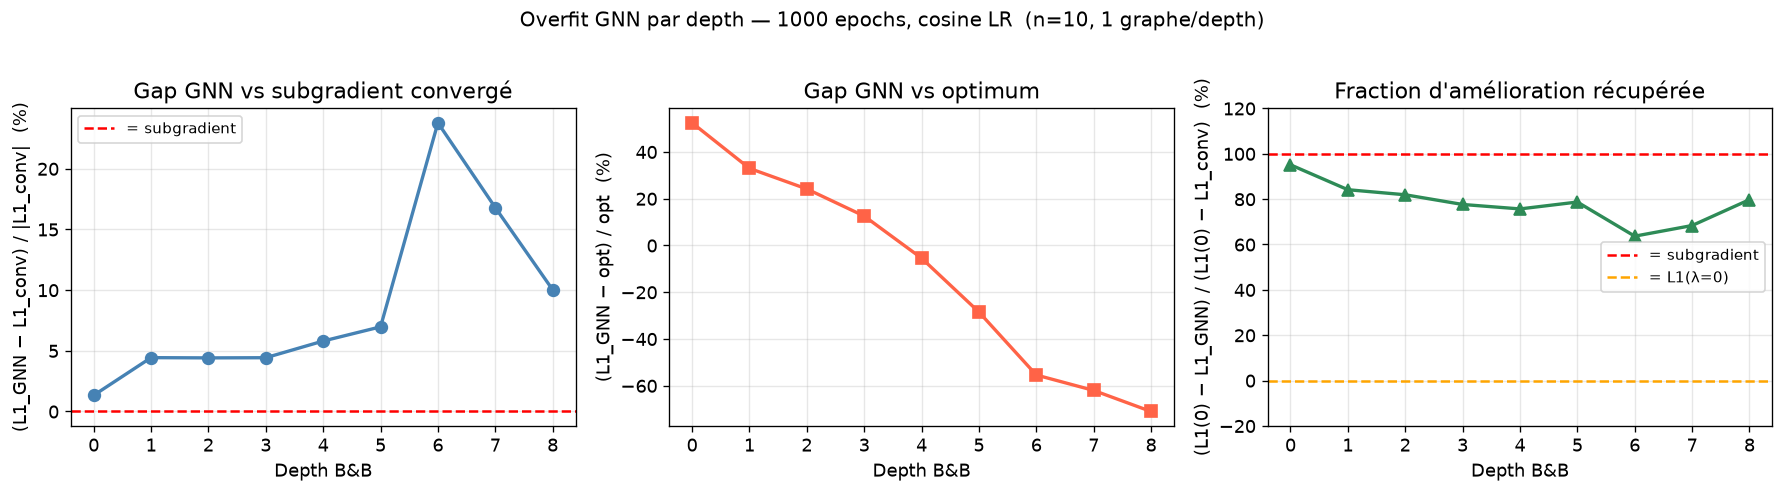

In [8]:
depths    = [r['depth']       for r in results]
gap_conv  = [r['gap_vs_conv'] for r in results]
gap_opt   = [r['gap_vs_opt']  for r in results]
frac_rec  = [r['frac_recov']  for r in results]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# ── Panel 1 : gap vs subgradient convergé ─────────────────────────────────────
axes[0].plot(depths, gap_conv, 'o-', color='steelblue', lw=2, ms=7)
axes[0].axhline(0, color='red', ls='--', lw=1.5, label='= subgradient')
axes[0].set_xlabel('Depth B&B')
axes[0].set_ylabel('(L1_GNN − L1_conv) / |L1_conv|  (%)')
axes[0].set_title('Gap GNN vs subgradient convergé')
axes[0].legend(fontsize=9)
axes[0].grid(True, alpha=0.3)

# ── Panel 2 : gap vs optimum ──────────────────────────────────────────────────
axes[1].plot(depths, gap_opt, 's-', color='tomato', lw=2, ms=7)
axes[1].set_xlabel('Depth B&B')
axes[1].set_ylabel('(L1_GNN − opt) / opt  (%)')
axes[1].set_title('Gap GNN vs optimum')
axes[1].grid(True, alpha=0.3)

# ── Panel 3 : fraction d'amélioration récupérée ───────────────────────────────
axes[2].plot(depths, frac_rec, '^-', color='seagreen', lw=2, ms=7)
axes[2].axhline(100, color='red',    ls='--', lw=1.5, label='= subgradient')
axes[2].axhline(0,   color='orange', ls='--', lw=1.5, label='= L1(λ=0)')
axes[2].set_ylim(-20, 120)
axes[2].set_xlabel('Depth B&B')
axes[2].set_ylabel('(L1(0) − L1_GNN) / (L1(0) − L1_conv)  (%)')
axes[2].set_title('Fraction d\'amélioration récupérée')
axes[2].legend(fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.suptitle(
    f"Overfit GNN par depth — {CFG['n_epochs']} epochs, cosine LR  "
    f"(n={N_VAL}, 1 graphe/depth)",
    y=1.02, fontsize=12)
plt.tight_layout()
plt.savefig(REPO / 'gnn' / 'depth_sweep.png', bbox_inches='tight')
plt.show()

## 7. (Optionnel) Courbes de convergence superposées

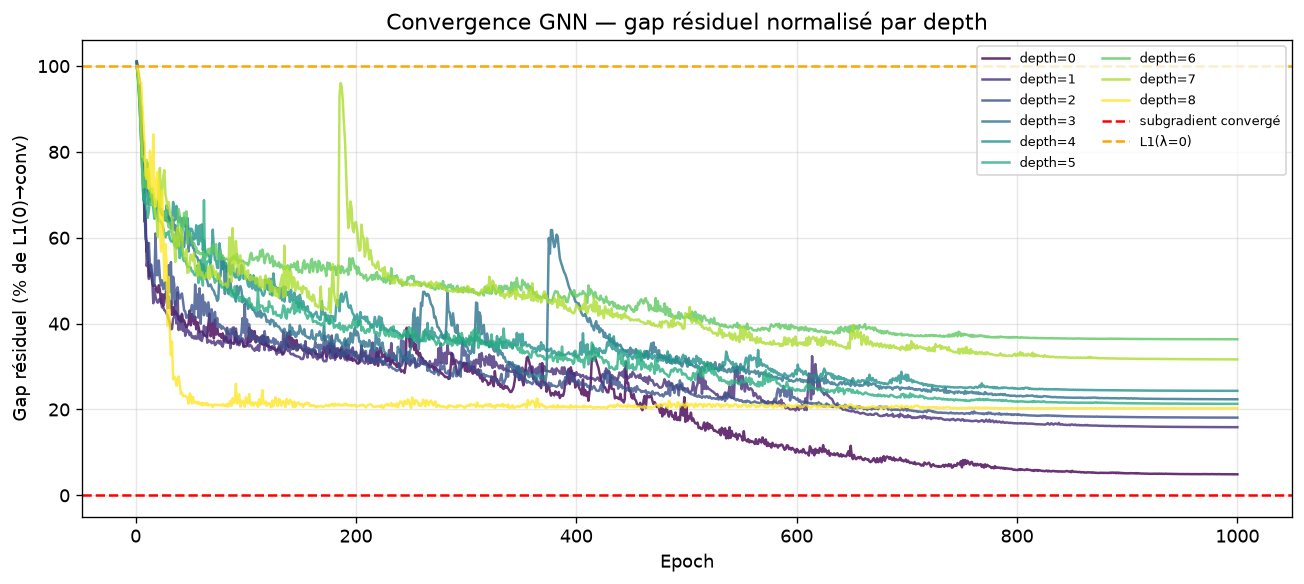

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
cmap = plt.cm.viridis
colors = [cmap(i / max(len(results) - 1, 1)) for i in range(len(results))]

for r, color in zip(results, colors):
    hist = r['history']
    # normaliser par L1(0) pour comparer les depths
    hist_norm = [(v - r['l1_conv']) / max(r['l1_init'] - r['l1_conv'], 1e-9) * 100
                 for v in hist]
    ax.plot(range(1, len(hist) + 1), hist_norm,
            color=color, lw=1.5, alpha=0.8, label=f"depth={r['depth']}")

ax.axhline(0,   color='red',    ls='--', lw=1.5, label='subgradient convergé')
ax.axhline(100, color='orange', ls='--', lw=1.5, label='L1(λ=0)')
ax.set_xlabel('Epoch')
ax.set_ylabel('Gap résiduel (% de L1(0)→conv)')
ax.set_title('Convergence GNN — gap résiduel normalisé par depth')
ax.legend(fontsize=8, ncol=2, loc='upper right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()